# Machine Learning Midterm - Wine Classification

This notebook covers Sections 1-10 for the Wine dataset. Shared functions are in `utils.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import utils

pd.set_option("display.max_columns", 50)
utils.make_folders()

DATASET = "wine"
display(utils.package_versions())

,package,version
0,python,3.14.3
1,numpy,2.5.4
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,scipy,1.18.1
5,matplotlib,3.11.2
6,seaborn,0.13.2


# 1. Loading the Dataset
## 1.1 Load the dataset from scikit-learn

In [2]:
X, y, class_names = utils.load_data(DATASET)
print("Loaded with load_wine()")

Loaded with load_wine()


### 1.2 Create the data frame (X and y are kept separate)

In [3]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Is the target inside X?", "target" in X.columns)
print("\nFeature names:", list(X.columns))
print("\nTarget labels:", sorted(int(v) for v in y.unique()))
print("Target names:", class_names)
display(X.head())

Shape of X: (178, 13)
Shape of y: (178,)
Is the target inside X? False

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target labels: [0, 1, 2]
Target names: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
display(utils.class_table(y, class_names))

,label,class_name,n_samples,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


**Interpretation.** The dataset has 178 samples and 13 numerical chemical features; the target is kept outside X. The class counts are class_0 = 59 (33.1%), class_1 = 71 (39.9%) and class_2 = 48 (27.0%). The imbalance is mild, but stratification and macro averaging are still used. The original labels 0, 1 and 2 are kept.

## 2. Dataset Quality Checks
### 2.1 Missing values and duplicates

In [5]:
missing = utils.missing_table(X)
display(missing)
print("Total missing values:", int(missing["missing_count"].sum()))
print("Duplicate rows:", utils.count_duplicates(X, y))
print("No missing values and no duplicate rows, so no imputation is needed.")

,feature,missing_count
0,alcohol,0
1,malic_acid,0
2,ash,0
3,alcalinity_of_ash,0
4,magnesium,0
5,total_phenols,0
6,flavanoids,0
7,nonflavanoid_phenols,0
8,proanthocyanins,0
9,color_intensity,0


Total missing values: 0
Duplicate rows: 0
No missing values and no duplicate rows, so no imputation is needed.


### 2.2 Potential outliers (IQR rule and |z| > 3) - nothing is removed

In [6]:
outliers = utils.outlier_table(X)
display(outliers)
print("Features with at least one IQR outlier:", int((outliers["n_iqr_outliers"] > 0).sum()), "of", X.shape[1])

,feature,iqr_lower,iqr_upper,n_iqr_outliers,n_abs_z_gt_3
4,magnesium,59.5000,135.5000,4,2
3,alcalinity_of_ash,10.7500,27.9500,4,1
9,color_intensity,-1.2500,10.6700,4,1
1,malic_acid,-0.6175,5.3025,3,1
2,ash,1.6887,3.0788,3,3
8,proanthocyanins,0.2000,3.0000,2,1
10,hue,0.2762,1.6263,1,1
0,alcohol,10.3900,15.6500,0,0
5,total_phenols,0.1563,4.3862,0,0
7,nonflavanoid_phenols,0.0188,0.6888,0,0


Features with at least one IQR outlier: 7 of 13


### 2.3 Data types

In [7]:
display(utils.dtype_table(X))
n_num = X.select_dtypes(include="number").shape[1]
print("Numerical features:", n_num, "| Categorical features:", X.shape[1] - n_num)

,feature,dtype
0,alcohol,float64
1,malic_acid,float64
2,ash,float64
3,alcalinity_of_ash,float64
4,magnesium,float64
5,total_phenols,float64
6,flavanoids,float64
7,nonflavanoid_phenols,float64
8,proanthocyanins,float64
9,color_intensity,float64


Numerical features: 13 | Categorical features: 0


**Interpretation** There are no missing values and no duplicate rows. All 13 features are float64 (13 numerical, 0 categorical). 7 of the 13 features have IQR outliers, but only a few each (at most 4, for `magnesium`, `alcalinity_of_ash` and `color_intensity`), so they are kept. The bigger issue is scale: `proline` ranges from 278 to 1680 and `magnesium` from 70 to 162, while `hue` lies between 0.48 and 1.71. In unscaled Euclidean distance (KNN, K-Means), `proline` therefore dominates. GaussianNB's mean and variance estimates are slightly pulled by the few extreme values. Decision trees are robust because they use thresholds.

## 3. Exploratory Data Analysis (EDA)
Sections 2-3 are descriptive only. They are not used to select features, fit preprocessing or remove samples.
### 3.1 Descriptive statistics

In [8]:
display(utils.describe_features(X))

,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000


### 3.2 Class distribution and correlations

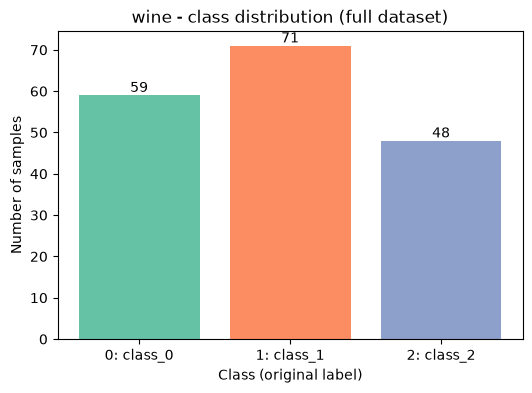

In [9]:
utils.plot_class_distribution(y, class_names, DATASET)

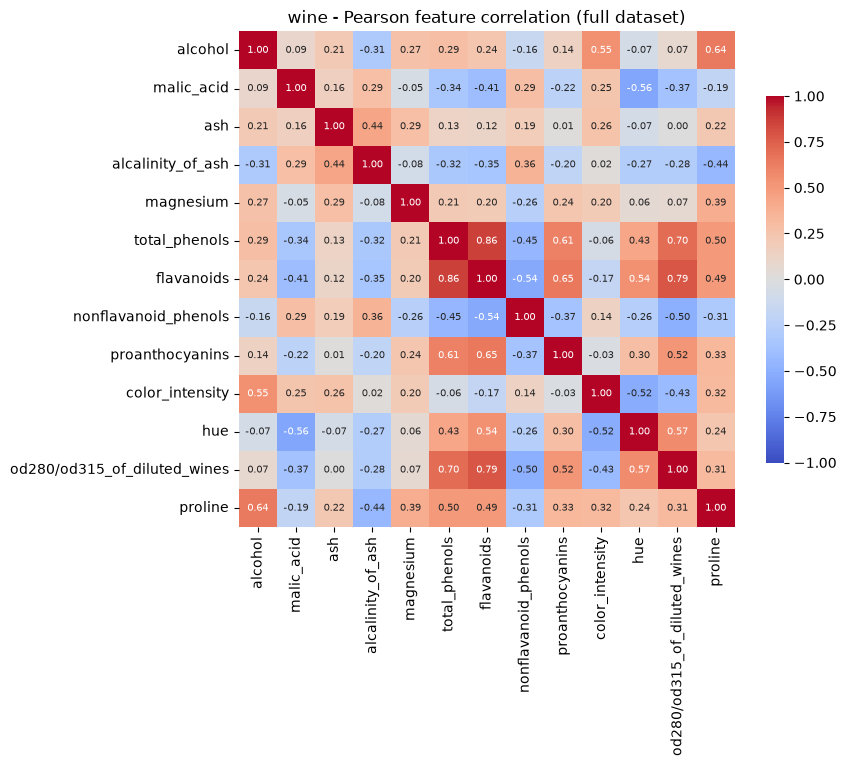

Three strongest unique feature pairs by |Pearson r|:


,feature_1,feature_2,pearson_r,abs_r
0,total_phenols,flavanoids,0.8646,0.8646
1,flavanoids,od280/od315_of_diluted_wines,0.7872,0.7872
2,total_phenols,od280/od315_of_diluted_wines,0.6999,0.6999


In [10]:
corr = utils.plot_corr_heatmap(X, DATASET)
print("Three strongest unique feature pairs by |Pearson r|:")
display(utils.top_corr_pairs(corr, n=3))

### 3.3 Boxplots

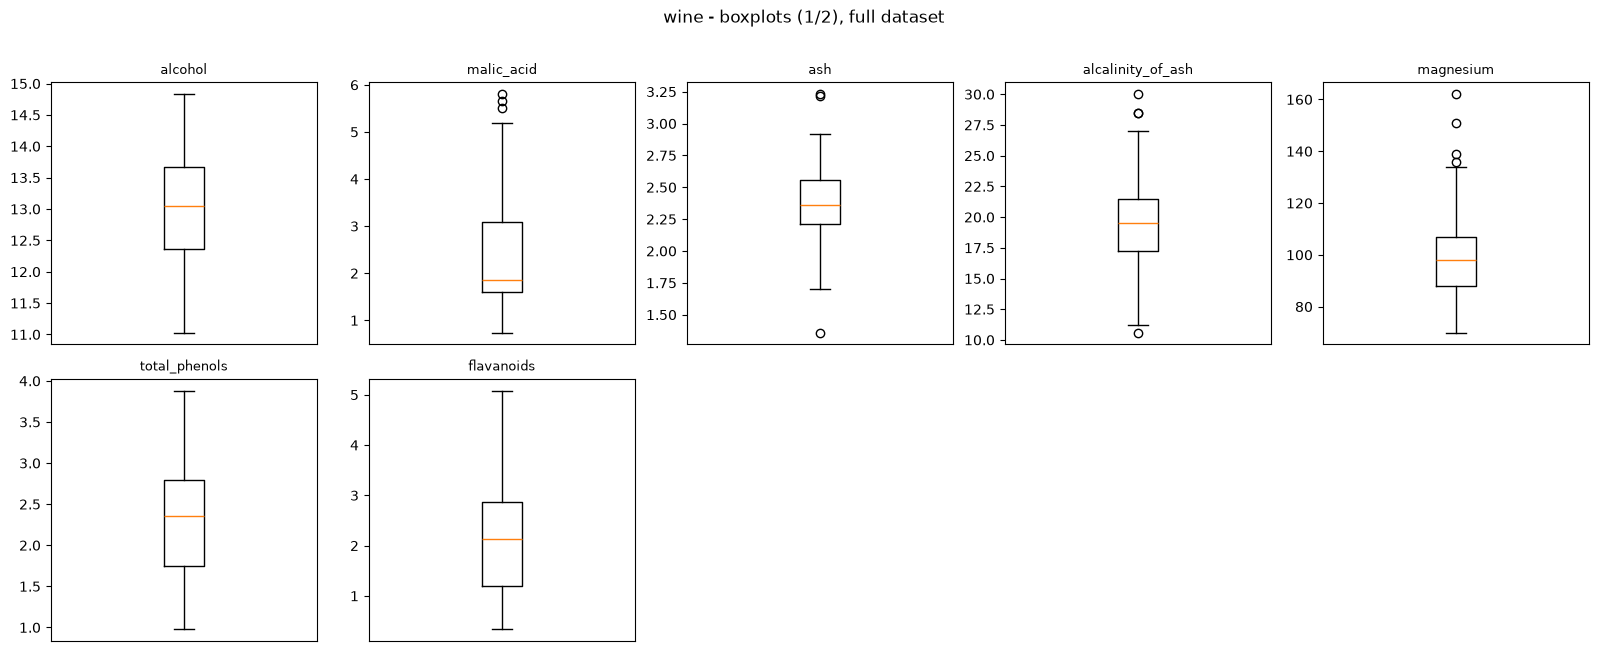

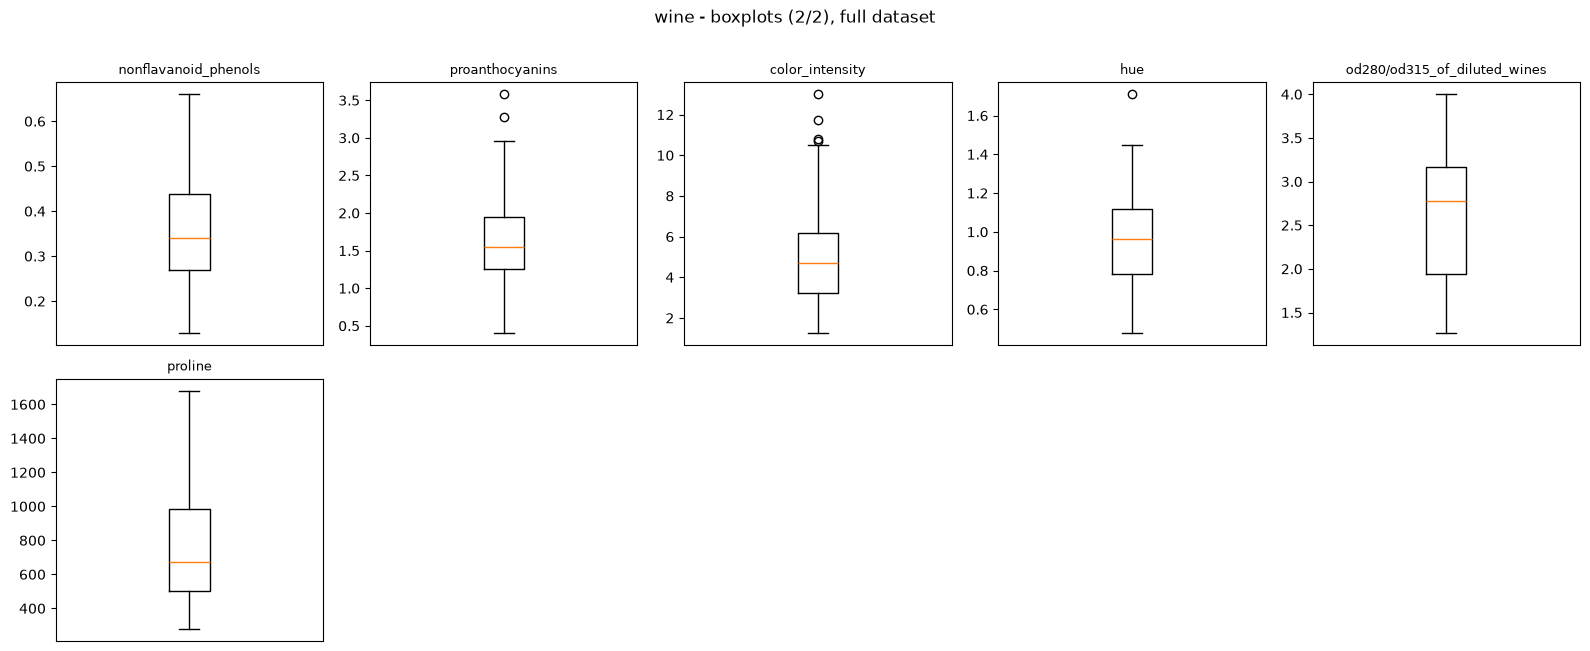

In [11]:
utils.plot_boxplots(X, DATASET, per_figure=7)

**Interpretation.** The features have very different ranges: `proline` has a mean of 746.9 and a standard deviation of 314.9, while `nonflavanoid_phenols` has a mean of 0.36 and a standard deviation of 0.12. `class_1` is the largest class. The three strongest unique correlations are `total_phenols`-`flavanoids` (r = 0.865), `flavanoids`-`od280/od315_of_diluted_wines` (r = 0.787) and `total_phenols`-`od280/od315_of_diluted_wines` (r = 0.700); these phenol-related measurements carry overlapping information. Boxplot observations: (1) `proline` and `magnesium` are on a much larger scale than the other features, and `magnesium` has visible high outliers; (2) `malic_acid` and `color_intensity` are right-skewed (mean > median: 2.34 vs 1.87 and 5.06 vs 4.69).

## 4. Splitting the Dataset
### 4.1 Fixed test set + repeated training/validation split
1. The 20% test set is reserved **once** with `test_size=0.20, stratify=y, random_state=42`.
2. For each seed in [42, 52, 62] the remaining 80% is split with `test_size=0.125`, stratified, `random_state=seed` (0.125 x 80% = 10% of the full dataset).

In [12]:
splits, X_test, y_test = utils.make_splits(X, y)
for seed in utils.SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, X_test {X_test.shape}")

seed 42: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 52: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 62: X_train (124, 13), X_val (18, 13), X_test (36, 13)


### 4.2 Verify the split

In [13]:
print(f"Split summary for {DATASET} (3 subsets x 3 seeds = 9 rows):")
display(utils.split_summary(splits, y_test, len(X), class_names))
display(utils.check_splits(splits, X_test, len(X)))

same_test = all(
    set(X_test.index) == set(X.index) - set(splits[s]["X_train"].index) - set(splits[s]["X_val"].index)
    for s in utils.SEEDS)
print("Test indices identical across all three repetitions:", same_test)

Split summary for wine (3 subsets x 3 seeds = 9 rows):


,seed,subset,n,percent,class_0_class_0,class_1_class_1,class_2_class_2
0,42,train,124,69.66,41,50,33
1,42,validation,18,10.11,6,7,5
2,42,test,36,20.22,12,14,10
3,52,train,124,69.66,41,50,33
4,52,validation,18,10.11,6,7,5
5,52,test,36,20.22,12,14,10
6,62,train,124,69.66,41,50,33
7,62,validation,18,10.11,6,7,5
8,62,test,36,20.22,12,14,10


,seed,train_val_overlap,train_test_overlap,val_test_overlap,total_rows,covers_full_dataset
0,42,0,0,0,178,True
1,52,0,0,0,178,True
2,62,0,0,0,178,True


Test indices identical across all three repetitions: True


In [14]:
idx_table, path = utils.save_split_indices(splits, X_test, DATASET)
show = idx_table[["seed", "subset", "n"]].copy()
show["first_10_indices"] = idx_table["original_row_indices"].str.split().str[:10]
display(show)
print("Full index lists saved to", path)

,seed,subset,n,first_10_indices
0,42,train,124,"[2, 3, 5, 8, 9, 11, 12, 13, 15, 16]"
1,42,validation,18,"[0, 1, 4, 6, 33, 35, 79, 86, 89, 97]"
2,42,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"
3,52,train,124,"[0, 1, 3, 4, 5, 6, 8, 9, 11, 12]"
4,52,validation,18,"[2, 31, 33, 34, 40, 45, 63, 69, 70, 91]"
5,52,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"
6,62,train,124,"[0, 1, 3, 4, 5, 6, 8, 11, 12, 13]"
7,62,validation,18,"[2, 9, 15, 25, 27, 29, 67, 68, 101, 107]"
8,62,test,36,"[7, 10, 14, 18, 20, 22, 28, 38, 42, 48]"


Full index lists saved to results\wine_split_indices.csv


**Interpretation.** For every seed the split is 124 / 18 / 36 rows (69.66% / 10.11% / 20.22%); integer rounding moves the percentages slightly away from 70/10/20. Stratification keeps the class counts at 41/50/33 (training), 6/7/5 (validation) and 12/14/10 (testing) for all seeds. The seeds change which rows are in training and validation, but the 36 test rows are identical in all three repetitions. There is no overlap between subsets and the three subsets always add up to 178 rows. Seed 42 is fixed in advance as the run used for the final test evaluation.

## 5. Data Preprocessing and Scaling
### 5.1 Missing values
Section 2 found **no missing values**, so no imputation step is added.
### 5.2 Selected scaler: StandardScaler
StandardScaler transforms every feature to z = (x - mean_train) / std_train. The same scaler type is used for both datasets and all three seeds.
### 5.3 Fit and apply the scaler correctly
A new scaler is fitted per seed on that seed's training features only (3 here, 6 across both datasets). Validation data are only transformed. The test set is transformed only with the seed-42 scaler.

In [15]:
reps, scalers, test_reps = utils.scale_data(splits, X_test)
for seed in utils.SEEDS:
    sc = scalers[seed]
    print(f"seed {seed}: scaler fitted on {int(sc.n_samples_seen_)} training rows; "
          f"first feature mean_train = {sc.mean_[0]:.4f}, std_train = {sc.scale_[0]:.4f}")

Xtr_s, _ = reps[42]["scaled"]
print("\nSeed-42 scaled training data: mean of every column ~ 0 ?",
      np.allclose(Xtr_s.mean().values, 0, atol=1e-9),
      "| std ~ 1 ?", np.allclose(Xtr_s.std(ddof=0).values, 1, atol=1e-9))

seed 42: scaler fitted on 124 training rows; first feature mean_train = 12.9738, std_train = 0.7874
seed 52: scaler fitted on 124 training rows; first feature mean_train = 12.9770, std_train = 0.7987
seed 62: scaler fitted on 124 training rows; first feature mean_train = 12.9483, std_train = 0.8250

Seed-42 scaled training data: mean of every column ~ 0 ? True | std ~ 1 ? True


In [16]:
print("Seed 42 - first five TRAINING rows BEFORE scaling:")
display(reps[42]["unscaled"][0].head())
print("Seed 42 - the same five TRAINING rows AFTER StandardScaler:")
display(reps[42]["scaled"][0].head().round(4))

Seed 42 - first five TRAINING rows BEFORE scaling:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Seed 42 - the same five TRAINING rows AFTER StandardScaler:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.0175,1.0892,-0.0401,-0.3084,0.4332,-1.3425,-1.3223,0.3527,-1.1176,0.1258,-1.2268,-1.2236,-0.2094
148,0.4397,0.8918,0.0729,0.6094,-0.5057,-0.4910,-1.2599,0.7699,-0.5719,1.5123,-1.8114,-1.4147,-0.2914
116,-1.4654,-0.7720,-1.3968,0.3953,-0.9081,-0.4121,-0.3865,-0.4819,-0.0789,-1.3445,-0.0125,1.0978,-0.8000
122,-0.7033,2.0104,1.3920,2.1391,0.1650,-0.0652,0.1645,0.6030,0.2380,-1.2871,-0.1475,0.7893,-1.2265
115,-2.4687,-0.7344,-0.6054,0.6094,-0.9752,0.3448,0.2061,1.3541,0.7661,-1.3665,3.4052,0.4219,-1.0887


**Interpretation.** StandardScaler was used, the same scaler type as for Breast Cancer. After scaling, each feature has a mean of 0 and a standard deviation of 1 on the training rows. For example, training row 163 has `proline` = 675, which becomes -0.21, and row 115 has `hue` = 1.71, which becomes +3.41 (an unusually high hue). Proline and hue now contribute on the same scale to a distance. The three scalers have slightly different `alcohol` means (12.974, 12.977, 12.948), which shows that each scaler was fitted only on its own training subset.

## 6. Preparing the Two Data Representations
* **Unscaled**: all original features (no imputation needed).
* **Scaled**: the same features and the same row indices after StandardScaler.

Both representations of a seed share exactly the same training and validation rows, so the only difference between them is scaling. No feature selection or dimensionality reduction is applied.

In [17]:
for seed in utils.SEEDS:
    (tr_u, va_u) = reps[seed]["unscaled"]
    (tr_s, va_s) = reps[seed]["scaled"]
    print(f"seed {seed}: same train rows = {tr_u.index.equals(tr_s.index)}, "
          f"same val rows = {va_u.index.equals(va_s.index)}, "
          f"features = {tr_u.shape[1]} / {tr_s.shape[1]}")

print("Test set: same rows =", test_reps["unscaled"].index.equals(test_reps["scaled"].index))

seed 42: same train rows = True, same val rows = True, features = 13 / 13
seed 52: same train rows = True, same val rows = True, features = 13 / 13
seed 62: same train rows = True, same val rows = True, features = 13 / 13
Test set: same rows = True


**Interpretation** For every seed, the unscaled and scaled versions contain exactly the same training and validation rows and all 13 original features. The fixed test set also has the same rows in both versions (scaled with the seed-42 scaler). Any difference between the two representations in Section 7 is therefore caused by scaling only.

## 7.Training the Classification Models
### 7.1 Required experiments
Decision Tree(max_depth = 2, 3, 5, 10, None; random_state = seed), KNN (k = 1, 3, 5, 7, 11; uniform weights; Euclidean distance) and GaussianNB (default settings) are trained on both representations under all three seeds: (5 + 5 + 1) x 2 x 3 = **66 runs** for this dataset. Every model is fitted on training data only; all other settings stay at their defaults.

In [18]:
runs, models_42 = utils.train_all_models(DATASET, reps, splits)
print("Number of classifier runs:", len(runs))
print("Runs per algorithm:", runs["algorithm"].value_counts().to_dict())
print("Example run IDs:", runs["run_id"].head(3).tolist())
print("Seed-42 fitted models kept for the final evaluation:", len(models_42))

Number of classifier runs: 66
Runs per algorithm: {'decision_tree': 30, 'knn': 30, 'gaussian_nb': 6}
Example run IDs: ['wine_dt_unscaled_d2_s42', 'wine_dt_unscaled_d3_s42', 'wine_dt_unscaled_d5_s42']
Seed-42 fitted models kept for the final evaluation: 22


### 7.2 Run-level table (66 rows: 22 configurations x 3 seeds)
Each run records the training accuracy and training macro-F1, followed by the five validation metrics.

In [19]:
show_cols = ["run_id", "seed", "algorithm", "representation", "parameter", "parameter_value",
             "train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
             "val_macro_recall", "val_macro_f1", "val_roc_auc"]
pd.set_option("display.max_rows", 100)
display(runs[show_cols].round(4))

undef = runs[runs["val_undefined_metrics"] != "none"]
print("Runs with undefined precision/recall before zero_division replacement:", len(undef))

,run_id,seed,algorithm,representation,parameter,parameter_value,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,wine_dt_unscaled_d2_s42,42,decision_tree,unscaled,max_depth,2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_dt_unscaled_d3_s42,42,decision_tree,unscaled,max_depth,3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_dt_unscaled_d5_s42,42,decision_tree,unscaled,max_depth,5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_dt_unscaled_d10_s42,42,decision_tree,unscaled,max_depth,10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_dt_unscaled_dNone_s42,42,decision_tree,unscaled,max_depth,None,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
5,wine_knn_unscaled_k1_s42,42,knn,unscaled,n_neighbors,1,1.0000,1.0000,0.6667,0.6750,0.6603,0.6646,0.7452
6,wine_knn_unscaled_k3_s42,42,knn,unscaled,n_neighbors,3,0.8468,0.8415,0.6111,0.6111,0.6016,0.6041,0.8003
7,wine_knn_unscaled_k5_s42,42,knn,unscaled,n_neighbors,5,0.7984,0.7837,0.7222,0.7159,0.7159,0.7128,0.8759
8,wine_knn_unscaled_k7_s42,42,knn,unscaled,n_neighbors,7,0.8145,0.8071,0.6667,0.6714,0.6683,0.6605,0.8405
9,wine_knn_unscaled_k11_s42,42,knn,unscaled,n_neighbors,11,0.7500,0.7405,0.6111,0.6159,0.6016,0.5998,0.8198


Runs with undefined precision/recall before zero_division replacement: 0


**Interpretation** All 66 runs were completed: 30 Decision Tree, 30 KNN and 6 GaussianNB fits. Every run has an ID containing the dataset, algorithm, representation, parameter and seed (for example `wine_knn_scaled_k5_s42`), and all runs are recorded, including the low-scoring ones. No validation run had a class with undefined precision or recall. The seed is part of the run ID; it is not a parameter to optimise. The 22 seed-42 models are kept for the final test evaluation.

## 8. Measuring Validation Performance
### 8.1 Metrics
Accuracy, macro precision, macro recall, macro F1 (`average="macro"`, `zero_division=0`) and ROC-AUC are calculated on each run's own validation subset. ROC-AUC uses the class probabilities with `multi_class="ovr"` and `average="macro"`; the probability columns follow the class order [0, 1, 2].
### 8.2 Summary across seeds (22 rows) and model selection
Mean and sample standard deviation (ddof=1) over seeds 42, 52 and 62. Selection rule: highest mean validation macro-F1, then mean validation accuracy, then lower macro-F1 std, then alphabetical configuration ID. Test results are never used.

In [20]:
summary = utils.summarize_runs(runs)
display(summary.round(4))

selected, ranked = utils.select_config(summary)
print("Top 5 configurations by the selection rule:")
display(ranked[["config_id", "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean"]].head(5).round(4))
SELECTED = selected["config_id"]
print("SELECTED CONFIGURATION:", SELECTED)

,dataset,config_id,algorithm,representation,parameter,parameter_value,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,n_seeds
0,wine,wine_dt_unscaled_d2,decision_tree,unscaled,max_depth,2,0.9355,0.0081,0.9365,0.0106,0.8519,0.0321,0.8724,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219,3
1,wine,wine_dt_unscaled_d3,decision_tree,unscaled,max_depth,3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431,3
2,wine,wine_dt_unscaled_d5,decision_tree,unscaled,max_depth,5,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
3,wine,wine_dt_unscaled_d10,decision_tree,unscaled,max_depth,10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
4,wine,wine_dt_unscaled_dNone,decision_tree,unscaled,max_depth,None,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
5,wine,wine_knn_unscaled_k1,knn,unscaled,n_neighbors,1,1.0000,0.0000,1.0000,0.0000,0.7037,0.0321,0.6886,0.0239,0.6836,0.0223,0.6714,0.0226,0.7654,0.0181,3
6,wine,wine_knn_unscaled_k3,knn,unscaled,n_neighbors,3,0.8360,0.0123,0.8294,0.0134,0.6667,0.0556,0.6614,0.0496,0.6519,0.0478,0.6456,0.0429,0.8333,0.0311,3
7,wine,wine_knn_unscaled_k5,knn,unscaled,n_neighbors,5,0.7876,0.0093,0.7739,0.0091,0.7037,0.0321,0.7280,0.0722,0.6862,0.0294,0.6667,0.0399,0.8645,0.0115,3
8,wine,wine_knn_unscaled_k7,knn,unscaled,n_neighbors,7,0.7903,0.0213,0.7804,0.0231,0.6667,0.0000,0.6471,0.0225,0.6545,0.0153,0.6356,0.0316,0.8459,0.0084,3
9,wine,wine_knn_unscaled_k11,knn,unscaled,n_neighbors,11,0.7392,0.0093,0.7309,0.0083,0.6296,0.0321,0.6148,0.0127,0.6138,0.0211,0.6005,0.0010,0.8216,0.0254,3


Top 5 configurations by the selection rule:


,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean
0,wine_knn_scaled_k11,0.9814,0.0323,0.9815
1,wine_knn_scaled_k5,0.9814,0.0323,0.9815
2,wine_knn_scaled_k7,0.9814,0.0323,0.9815
3,wine_knn_scaled_k1,0.9658,0.0296,0.9630
4,wine_gnb_scaled,0.9638,0.0314,0.9630


SELECTED CONFIGURATION: wine_knn_scaled_k11


In [21]:
scaling = summary.pivot_table(index=["algorithm", "parameter_value"], columns="representation",
                              values="val_macro_f1_mean").round(4)
scaling["scaled_minus_unscaled"] = (scaling["scaled"] - scaling["unscaled"]).round(4)
print("Scaling effect on mean validation macro-F1:")
display(scaling)

gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean"]].copy()
gap["train_minus_val"] = (gap["train_macro_f1_mean"] - gap["val_macro_f1_mean"]).round(4)
print("Largest training/validation gaps:")
display(gap.sort_values("train_minus_val", ascending=False).head(5).round(4))

print("Largest variability across seeds (val macro-F1 std):")
display(summary[["config_id", "val_macro_f1_std"]].sort_values("val_macro_f1_std", ascending=False).head(5).round(4))

Scaling effect on mean validation macro-F1:


representation                 scaled  unscaled  scaled_minus_unscaled
algorithm     parameter_value                                         
decision_tree 10               0.9462    0.9462                 0.0000
              2                0.8481    0.8481                 0.0000
              3                0.9462    0.9462                 0.0000
              5                0.9462    0.9462                 0.0000
              None             0.9462    0.9462                 0.0000
gaussian_nb   default          0.9638    0.9638                 0.0000
knn           1                0.9658    0.6714                 0.2944
              11               0.9814    0.6005                 0.3809
              3                0.9457    0.6456                 0.3001
              5                0.9814    0.6667                 0.3147
              7                0.9814    0.6356                 0.3458

Largest training/validation gaps:


,config_id,train_macro_f1_mean,val_macro_f1_mean,train_minus_val
5,wine_knn_unscaled_k1,1.0000,0.6714,0.3286
6,wine_knn_unscaled_k3,0.8294,0.6456,0.1838
8,wine_knn_unscaled_k7,0.7804,0.6356,0.1448
9,wine_knn_unscaled_k11,0.7309,0.6005,0.1304
7,wine_knn_unscaled_k5,0.7739,0.6667,0.1072


Largest variability across seeds (val macro-F1 std):


,config_id,val_macro_f1_std
17,wine_knn_scaled_k3,0.0558
1,wine_dt_unscaled_d3,0.0545
4,wine_dt_unscaled_dNone,0.0545
3,wine_dt_unscaled_d10,0.0545
12,wine_dt_scaled_d3,0.0545


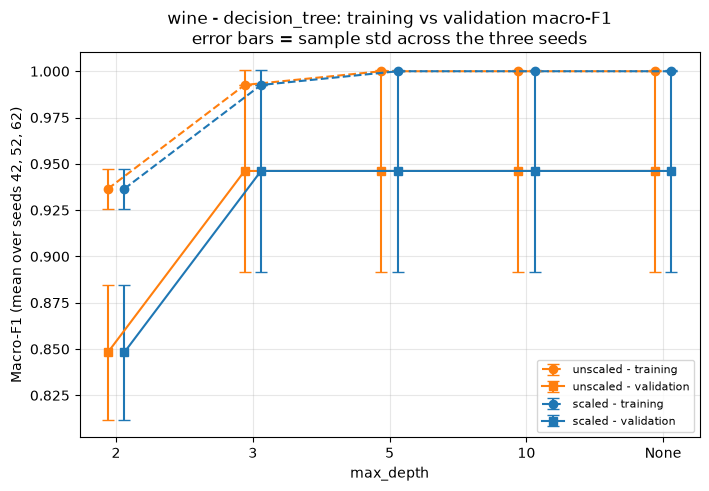

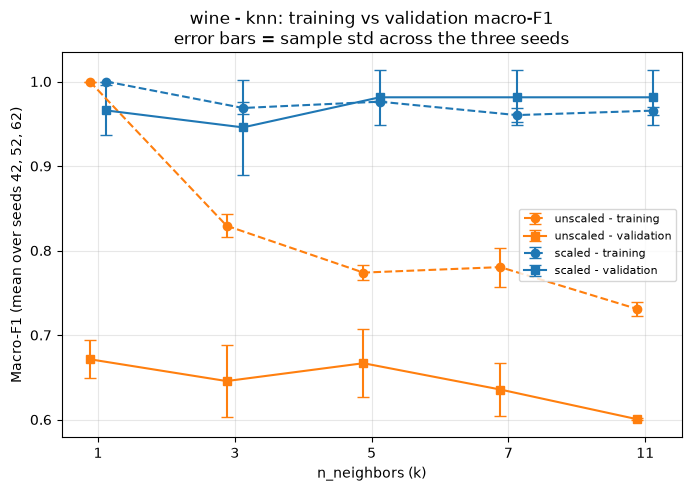

In [22]:
utils.plot_param_curve(summary, DATASET, "decision_tree", "max_depth", f"{DATASET}_tree_depth_comparison.png")
utils.plot_param_curve(summary, DATASET, "knn", "n_neighbors (k)", f"{DATASET}_knn_k_comparison.png")

**Interpretation.** **Selected configuration: `wine_knn_scaled_k11`.** Three configurations (scaled KNN with k = 5, 7 and 11) are exactly tied on mean validation macro-F1 (0.9814), mean accuracy (0.9815) and std (0.0323), so the predefined tie-break falls through to the alphabetical configuration ID: "wine_knn_scaled_k11" sorts before "..._k5" and "..._k7". Test performance was not used.

*Scaling.* Scaling has the largest effect on KNN: macro-F1 increases by +0.29 to +0.38 (for example k = 11: 0.6005 unscaled to 0.9814 scaled). Unscaled KNN even has a low training F1 (0.73-0.83 for k ≥ 3), which is underfitting caused by `proline` dominating the distance. Decision Tree and GaussianNB give identical results in both representations (difference 0.0000).

*Tree depth.* Depth 2 is too shallow (validation F1 = 0.848). From depth 3 onwards, validation F1 stays at 0.946, while training F1 reaches 1.000 at depth 5, so extra depth only memorises the training data.

*Neighbour count.* For scaled KNN, k = 1 (0.966) and k = 3 (0.946) are lower than k = 5-11 (0.981). For unscaled KNN, larger k does not help (0.60-0.67), so a larger k is not always better.

*Variability.* There are only 18 validation rows, so one error changes accuracy by 5.6 percentage points. Standard deviations reach 0.056 (scaled KNN k = 3 and the deeper trees), so the ranking among the top configurations is uncertain. The standard deviation describes three overlapping repeated splits; it is not a confidence interval.

## 9. Evaluating the Selected Model on the Test Set
The selection above is frozen. Only the **seed-42 fitted instance** of the selected configuration is evaluated, once, using the seed-42 preprocessing. No refitting, no other candidates and no other seeds.
### 9.1 Final performance metrics

In [23]:
final_model = models_42[SELECTED]
final_rep = selected["representation"]
X_test_final = test_reps[final_rep]
print("Selected configuration:", SELECTED, "| representation:", final_rep, "| evaluation seed: 42")
print("Model:", final_model)

tm = utils.get_metrics(DATASET, final_model, X_test_final, y_test, "test")
final_table = pd.DataFrame([{
    "dataset": DATASET, "selected_configuration": SELECTED, "evaluation_seed": 42,
    "val_macro_f1_mean": selected["val_macro_f1_mean"], "val_macro_f1_std": selected["val_macro_f1_std"],
    "test_accuracy": tm["test_accuracy"], "test_macro_precision": tm["test_macro_precision"],
    "test_macro_recall": tm["test_macro_recall"], "test_macro_f1": tm["test_macro_f1"],
    "test_roc_auc": tm["test_roc_auc"], "test_undefined_metrics": tm["test_undefined_metrics"]}])
display(final_table.round(4))

y_test_pred = final_model.predict(X_test_final)
print(utils.classification_report(y_test, y_test_pred, labels=[0, 1, 2],
                                  target_names=class_names, digits=4, zero_division=0))

Selected configuration: wine_knn_scaled_k11 | representation: scaled | evaluation seed: 42
Model: KNeighborsClassifier(metric='euclidean', n_neighbors=11)


,dataset,selected_configuration,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc,test_undefined_metrics
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0,none


              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



### 9.2 Confusion matrix (rows = Actual, columns = Predicted)
The complete 3 × 3 matrix is shown with class order [0, 1, 2]. Off-diagonal cells are errors.

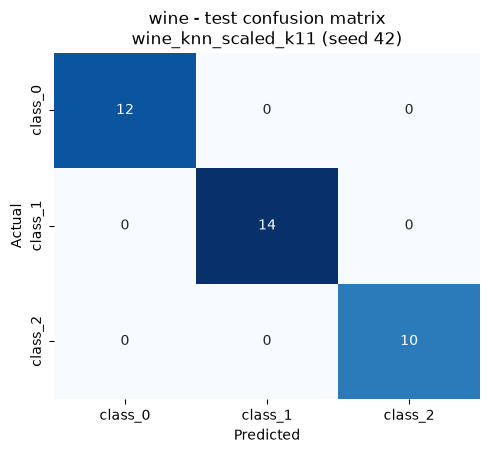

No off-diagonal errors: every test sample was classified correctly.
Total errors: 0 of 36


In [24]:
labels = [0, 1, 2]
cm = utils.confusion_matrix(y_test, y_test_pred, labels=labels)
utils.plot_confusion(cm, class_names, f"{DATASET} - test confusion matrix\n{SELECTED} (seed 42)",
                     f"{DATASET}_confusion_matrix.png")
off = cm.copy()
np.fill_diagonal(off, 0)
if off.sum() == 0:
    print("No off-diagonal errors: every test sample was classified correctly.")
else:
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Largest off-diagonal confusion: {off[i, j]} sample(s) of actual {class_names[i]} "
          f"predicted as {class_names[j]}")
print("Total errors:", int(off.sum()), "of", int(cm.sum()))

In [25]:
CHOSEN = 1   # class_1 vs all other classes
manual = utils.manual_metrics(cm, CHOSEN, class_names)
display(pd.DataFrame([manual]).round(4))

report = utils.classification_report(y_test, y_test_pred, labels=labels, target_names=class_names,
                                     output_dict=True, zero_division=0)[class_names[CHOSEN]]
print("classification_report, %s row: precision = %.4f, recall = %.4f, f1 = %.4f"
      % (class_names[CHOSEN], report["precision"], report["recall"], report["f1-score"]))
print("Manual values match the report:",
      np.allclose([manual["precision = TP/(TP+FP)"], manual["recall = TP/(TP+FN)"], manual["F1 = 2PR/(P+R)"]],
                  [report["precision"], report["recall"], report["f1-score"]]))

,class,TP,FP,FN,TN,precision = TP/(TP+FP),recall = TP/(TP+FN),F1 = 2PR/(P+R)
0,1 (class_1),14,0,0,22,1.0,1.0,1.0


classification_report, class_1 row: precision = 1.0000, recall = 1.0000, f1 = 1.0000
Manual values match the report: True


**Interpretation** The selected seed-42 model classifies all 36 test samples correctly: accuracy, macro-precision, macro-recall, macro-F1 and ROC-AUC are all 1.000. This is slightly above the mean validation macro-F1 (0.981 ± 0.032), which is within the expected variation for such small subsets. The selection was not changed after seeing the test results.

Confusion matrix: all counts are on the diagonal (12, 14, 10) and every off-diagonal cell is 0, so there is no largest confusion to explain. Manual one-vs-rest check for class_1: TP = 14, FP = 0, FN = 0, TN = 22, so precision = 14 / 14 = 1.0000, recall = 14 / 14 = 1.0000 and F1 = 1.0000. These values match the class_1 row of the classification report (not the macro averages).

### 9.3 ROC curve

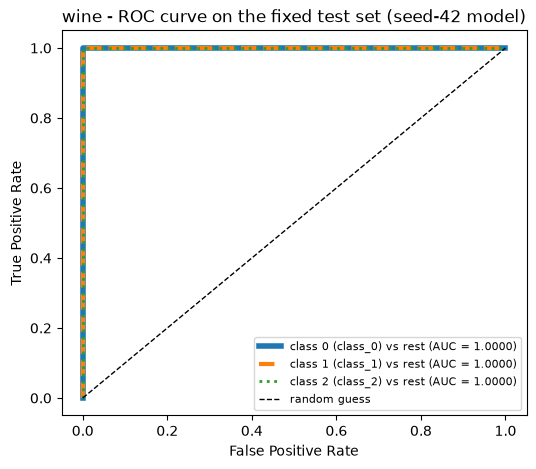

,curve,AUC
0,class 0 (class_0) vs rest,1.0
1,class 1 (class_1) vs rest,1.0
2,class 2 (class_2) vs rest,1.0
3,macro OvR AUC,1.0


In [26]:
aucs = utils.plot_roc(DATASET, final_model, X_test_final, y_test, class_names, f"{DATASET}_roc_curve.png")
display(pd.DataFrame({"curve": list(aucs.keys()), "AUC": [round(v, 4) for v in aucs.values()]}))

### 9.4 Error interpretation

In [27]:
wrong = utils.wrong_predictions(final_model, X_test_final, y_test, class_names)
print("Misclassified test samples:", len(wrong), "of", len(y_test))
display(wrong)

Misclassified test samples: 0 of 36


""


**Interpretation** *ROC.* Every one-vs-rest curve goes straight up to TPR = 1 at FPR = 0 (AUC = 1.000 for each class; macro OvR AUC = 1.000), because every sample of a class receives a higher probability for that class than any other sample does. The three curves lie on top of each other. A sample is assigned to a class when its probability passes the decision threshold. Lowering the threshold for a class would add false positives without reducing false negatives, which are already zero; raising it too far would start creating false negatives. No threshold was tuned on the test set.

*Errors.* The selected classifier made no test errors, so there is no misclassification to describe. One error-free result on 36 samples does not prove perfect generalisation: an error rate of up to about 8% (rule of three: 3 / 36) is still plausible, and the validation repetitions did contain errors (mean validation accuracy 0.981). *Limitations:* the validation subsets have only 18 rows, the repetitions overlap, and only the predeclared seed-42 model was tested once.

## 10.K-Means Clustering
K-Means is unsupervised: it is fitted on training **features only** (`y_train` is never passed to `fit`). n_clusters = 3 (fixed from the number of classes, not searched), `random_state=seed`, `n_init=10` (10 internal initialisations inside one fit, not extra experiments). 2 representations x 3 seeds = 6 fits. K-Means cluster IDs are not class labels.
### 10.1 Fit the clustering model

In [28]:
N_CLUSTERS = 3
km_runs, kmeans_42 = utils.run_kmeans(DATASET, reps, splits, N_CLUSTERS)
print("K-Means fits:", len(km_runs))
display(km_runs.round(4))

km_summary = utils.summarize_kmeans(km_runs)
print("Across-seed summary (one row per representation). Raw inertia is NOT comparable "
      "between scaled and unscaled spaces because the units differ.")
display(km_summary.round(4))

K-Means fits: 6


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_silhouette_note,val_cluster_counts
0,wine,wine_kmeans_unscaled_c3_s42,42,unscaled,3,10,1.350496e+06,0.2828,0.4870,ok,"[8, 4, 6]"
1,wine,wine_kmeans_scaled_c3_s42,42,scaled,3,10,8.747391e+02,1.0000,0.2516,ok,"[6, 7, 5]"
2,wine,wine_kmeans_unscaled_c3_s52,52,unscaled,3,10,1.303675e+06,0.4006,0.5559,ok,"[9, 5, 4]"
3,wine,wine_kmeans_scaled_c3_s52,52,scaled,3,10,8.904355e+02,1.0000,0.3010,ok,"[7, 5, 6]"
4,wine,wine_kmeans_unscaled_c3_s62,62,unscaled,3,10,1.390754e+06,0.4006,0.6867,ok,"[5, 4, 9]"
5,wine,wine_kmeans_scaled_c3_s62,62,scaled,3,10,8.722466e+02,1.0000,0.2726,ok,"[6, 5, 7]"


Across-seed summary (one row per representation). Raw inertia is NOT comparable between scaled and unscaled spaces because the units differ.


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,n_valid_silhouette_seeds,n_seeds
0,wine,unscaled,1.348308e+06,43580.9098,0.3613,0.068,0.5765,0.1014,3,3
1,wine,scaled,8.791404e+02,9.8609,1.0000,0.000,0.2751,0.0248,3,3


**Interpretation** Unscaled K-Means has a mean validation ARI of 0.361 (std 0.068) and a mean silhouette of 0.577. Scaled K-Means has a mean ARI of 1.000 (std 0.000): it reproduced the true classes perfectly on all three validation sets. Its mean silhouette is 0.275. The silhouette was defined for all seeds. Inertia is not compared across representations because it is measured in different units (about 1.3 x 10^6 unscaled vs about 9 x 10^2 scaled).

### 10.2 Final cluster evaluation on the fixed test set (seed-42 models, no new fits)
Both representations are evaluated; neither is selected by its test score. True labels are used only to evaluate the clusters (ARI and contingency tables), never to fit or rename them.

In [29]:
km_test_rows = []
for rep in utils.REPRESENTATIONS:
    Xt = test_reps[rep]
    clusters = kmeans_42[rep].predict(Xt)
    sil, note = utils.safe_silhouette(Xt, clusters)
    counts = np.bincount(clusters, minlength=N_CLUSTERS).tolist()
    km_test_rows.append({"dataset": DATASET, "representation": rep, "seed": 42,
                         "test_cluster_counts": str(counts),
                         "test_ari": utils.adjusted_rand_score(y_test, clusters),
                         "test_silhouette": sil, "silhouette_note": note})
    table = pd.crosstab(pd.Series(y_test.map(lambda c: f"{c} ({class_names[c]})").values, name="true class"),
                        pd.Series(clusters, name="cluster ID"))
    print(f"\nClass-versus-cluster contingency table - {DATASET}, {rep}, seed 42, test set:")
    display(table)

km_test = pd.DataFrame(km_test_rows)
display(km_test.round(4))


Class-versus-cluster contingency table - wine, unscaled, seed 42, test set:


cluster ID,0,1,2
true class,,,
0 (class_0),2,10,0
1 (class_1),5,0,9
2 (class_2),7,0,3



Class-versus-cluster contingency table - wine, scaled, seed 42, test set:


cluster ID,0,1,2
true class,,,
0 (class_0),12,0,0
1 (class_1),1,13,0
2 (class_2),0,0,10


,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette,silhouette_note
0,wine,unscaled,42,"[14, 10, 12]",0.3733,0.4929,ok
1,wine,scaled,42,"[13, 13, 10]",0.9088,0.2711,ok


### 10.3 Visualise the clusters

Two original features chosen from seed-42 TRAINING data: flavanoids and proline


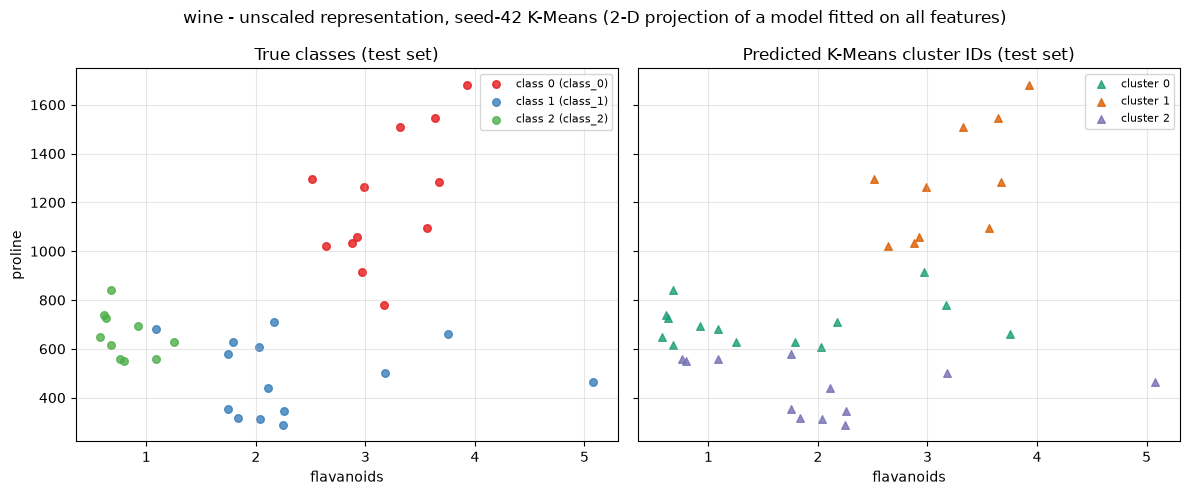

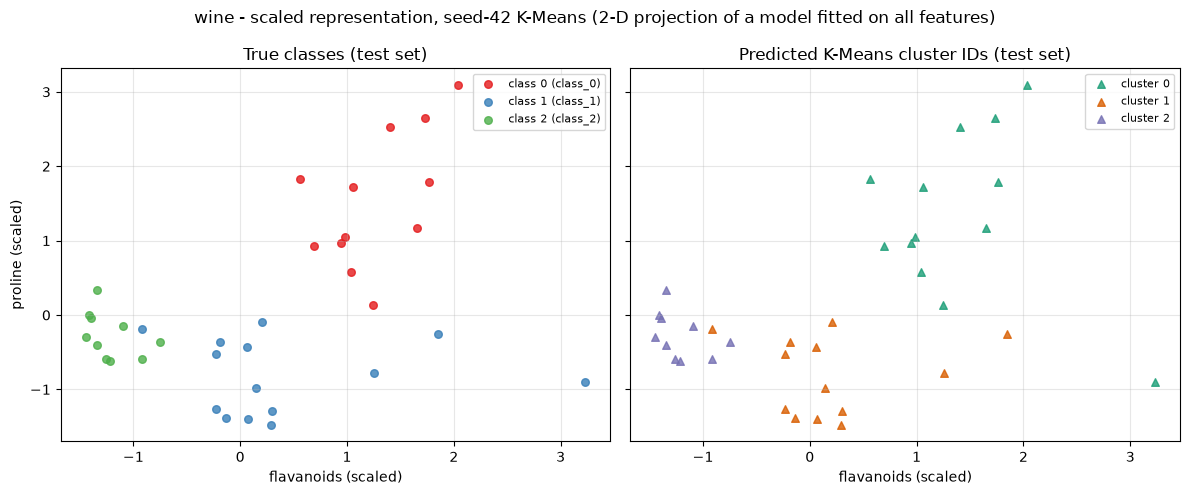

In [30]:
f1_name, f2_name = utils.choose_two_features(splits[42]["X_train"], splits[42]["y_train"])
print("Two original features chosen from seed-42 TRAINING data:", f1_name, "and", f2_name)
for rep in utils.REPRESENTATIONS:
    Xt = test_reps[rep]
    clusters = kmeans_42[rep].predict(Xt)
    utils.plot_class_vs_cluster(Xt, y_test, clusters, f1_name, f2_name, DATASET, rep, class_names,
                                f"{DATASET}_kmeans_{rep}_class_vs_cluster.png")

**Interpretation.** *Test (seed 42).* Unscaled: cluster sizes 14, 10 and 12, ARI = 0.373. The classes are strongly mixed: class_1 is split over clusters 2 (9) and 0 (5), and class_2 over clusters 0 (7) and 2 (3), because the partition mainly follows `proline`. Scaled: cluster sizes 13, 13 and 10, ARI = 0.909. Each cluster corresponds to one class, and only one class_1 sample falls into the cluster that otherwise contains class_0. Scaling therefore changes the partition completely. The unscaled silhouette is higher (0.493 vs 0.271) only because it is measured in proline-dominated units, so it is not evidence of a better clustering.

*Plots.* `flavanoids` and `proline` were chosen from the seed-42 training data (the highest ANOVA F-score, then the next strong feature with |r| < 0.8). The plots show only a 2-D projection of models fitted on all 13 features.

*Information available.* K-Means saw only the training features and grouped samples by distance; it had no access to `y_train`, and its cluster IDs are arbitrary. The classifiers were trained with the labels. That the scaled clusters still match the classes so well shows that the three wine cultivars form naturally separated groups in the standardised chemical space.